In [33]:
!pip install requests beautifulsoup4 pandas

In [34]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [35]:
url = "https://books.toscrape.com/catalogue/category/books/food-and-drink_33/index.html"

In [36]:
response = requests.get(url)

print("Status Code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.text)

Status Code: 200

    Food and Drink | 
     Books to Scrape - Sandbox




In [37]:
books = soup.find_all("h3")

for book in books:
    print(book.get_text(strip=True))

Foolproof Preserving: A Guide ...
The Pioneer Woman Cooks: ...
My Paris Kitchen: Recipes ...
Mama Tried: Traditional Italian ...
Layered: Baking, Building, and ...
The Nerdy Nummies Cookbook: ...
The Love and Lemons ...
The Cookies & Cups ...
Deliciously Ella Every Day: ...
The Help Yourself Cookbook ...
It's All Easy: Healthy, ...
Barefoot Contessa Back to ...
Barefoot Contessa at Home: ...
My Kitchen Year: 136 ...
Everyday Italian: 125 Simple ...
A la Mode: 120 ...
Cravings: Recipes for What ...
The Moosewood Cookbook: Recipes ...
32 Yolks
Naturally Lean: 125 Nourishing ...


In [38]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://www.scrapethissite.com/pages/forms/"

response = requests.get(url)

print("Status Code:", response.status_code)

soup_table = BeautifulSoup(response.text, "html.parser")

table = soup_table.find("table")

print(table)

Status Code: 200
<table class="table">
<tr>
<th>
                            Team Name
                        </th>
<th>
                            Year
                        </th>
<th>
                            Wins
                        </th>
<th>
                            Losses
                        </th>
<th>
                            OT Losses
                        </th>
<th>
                            Win %
                        </th>
<th>
                            Goals For (GF)
                        </th>
<th>
                            Goals Against (GA)
                        </th>
<th>
                            + / -
                        </th>
</tr>
<tr class="team">
<td class="name">
                            Boston Bruins
                        </td>
<td class="year">
                            1990
                        </td>
<td class="wins">
                            44
                        </td>
<td class="losses">
            

In [39]:
rows = table.find_all("tr")

data = []

for row in rows:
    cells = row.find_all(["th", "td"])
    row_data = [cell.get_text(strip=True) for cell in cells]

    if row_data:
        data.append(row_data)

df_table = pd.DataFrame(data)

print(df_table.head())

                    0     1     2       3          4      5               6  \
0           Team Name  Year  Wins  Losses  OT Losses  Win %  Goals For (GF)   
1       Boston Bruins  1990    44      24              0.55             299   
2      Buffalo Sabres  1990    31      30             0.388             292   
3      Calgary Flames  1990    46      26             0.575             344   
4  Chicago Blackhawks  1990    49      23             0.613             284   

                    7      8  
0  Goals Against (GA)  + / -  
1                 264     35  
2                 278     14  
3                 263     81  
4                 211     73  


In [40]:
df_table.to_csv("scraped_table.csv", index=False, header=False)

In [41]:
print("CSV file created successfully!")

CSV file created successfully!


In [42]:
from google.colab import files

files.download("scraped_table.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
df_table = pd.DataFrame(data)

print(df_table.head())

df_table.to_csv("scraped_table.csv", index=False, header=False)

print("CSV file created successfully!")

                    0     1     2       3          4      5               6  \
0           Team Name  Year  Wins  Losses  OT Losses  Win %  Goals For (GF)   
1       Boston Bruins  1990    44      24              0.55             299   
2      Buffalo Sabres  1990    31      30             0.388             292   
3      Calgary Flames  1990    46      26             0.575             344   
4  Chicago Blackhawks  1990    49      23             0.613             284   

                    7      8  
0  Goals Against (GA)  + / -  
1                 264     35  
2                 278     14  
3                 263     81  
4                 211     73  
CSV file created successfully!


In [44]:
from google.colab import files

files.download("scraped_table.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Practical - 2

In [48]:
import pandas as pd

df = pd.read_csv("food_delivery_dataset.csv")

print(df.head())

    order_id  restaurant_id     food_item  order_time delivery_time  \
0  ORD000001             16        Taccos  2024-01-31    2024-01-31   
1  ORD000002             30  Briyani rice  2024-10-16    2024-10-16   
2  ORD000003              3         Pasta  2024-09-11    2024-09-11   
3  ORD000004             93    Whole cake  2024-09-17    2024-09-17   
4  ORD000005             15         Sushi  2024-08-26    2024-08-26   

   delivery_distance  order_value delivery_method traffic_condition  \
0               2.17        42.21            Bike            Medium   
1              13.40        24.82             Car              High   
2              10.74        37.25            Walk              High   
3               6.29        49.88            Bike              High   
4               2.94         8.53            Walk               Low   

  weather_condition  ...  food_temperature food_freshness packaging_quality  \
0             Snowy  ...               Hot            5.0          

In [49]:
print("Rows and Columns:", df.shape)
print("Columns",df.columns)
df.info()
df.describe()

Rows and Columns: (16038, 31)
Columns Index(['order_id', 'restaurant_id', 'food_item', 'order_time', 'delivery_time',
       'delivery_distance', 'order_value', 'delivery_method',
       'traffic_condition', 'weather_condition', 'delivery_delay',
       'route_taken', 'customer_id', 'age', 'gender', 'location',
       'order_history', 'customer_rating', 'preferred_cuisine',
       'order_frequency', 'loyalty_program', 'food_temperature',
       'food_freshness', 'packaging_quality', 'food_condition',
       'customer_satisfaction', 'small_route', 'bike_friendly_route',
       'route_type', 'route_efficiency', 'traffic_avoidance'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16038 entries, 0 to 16037
Data columns (total 31 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               16038 non-null  object 
 1   restaurant_id          16038 non-null  int64  
 2   food_item        

,restaurant_id,delivery_distance,order_value,delivery_delay,age,order_history,customer_rating,food_freshness,packaging_quality,customer_satisfaction,route_efficiency
count,16038.000000,16037.000000,16037.000000,16037.000000,16037.000000,16037.000000,16037.00000,16037.000000,16037.000000,16037.000000,16037.000000
mean,50.396558,8.486923,27.337967,4.972232,38.886887,25.808505,3.02831,2.993453,3.007794,2.981667,0.496505
std,28.688699,3.772979,13.060245,8.630234,12.408836,14.313959,1.41697,1.417656,1.414919,1.414359,0.287276
min,1.000000,2.000000,5.000000,-10.000000,18.000000,1.000000,1.00000,1.000000,1.000000,1.000000,0.000276
25%,26.000000,5.210000,15.850000,-2.420000,28.000000,14.000000,2.00000,2.000000,2.000000,2.000000,0.245757
50%,50.000000,8.440000,27.220000,4.900000,39.000000,26.000000,3.00000,3.000000,3.000000,3.000000,0.494123
75%,75.000000,11.820000,38.770000,12.340000,50.000000,38.000000,4.00000,4.000000,4.000000,4.000000,0.743402
max,100.000000,15.000000,49.990000,20.000000,60.000000,50.000000,5.00000,5.000000,5.000000,5.000000,0.999841


In [50]:
print(df.isnull().sum())

order_id                 0
restaurant_id            0
food_item                0
order_time               0
delivery_time            0
delivery_distance        1
order_value              1
delivery_method          1
traffic_condition        1
weather_condition        1
delivery_delay           1
route_taken              1
customer_id              1
age                      1
gender                   1
location                 1
order_history            1
customer_rating          1
preferred_cuisine        1
order_frequency          1
loyalty_program          1
food_temperature         1
food_freshness           1
packaging_quality        1
food_condition           1
customer_satisfaction    1
small_route              1
bike_friendly_route      1
route_type               1
route_efficiency         1
traffic_avoidance        1
dtype: int64


In [51]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [52]:
print(df.dtypes)

order_id                  object
restaurant_id              int64
food_item                 object
order_time                object
delivery_time             object
delivery_distance        float64
order_value              float64
delivery_method           object
traffic_condition         object
weather_condition         object
delivery_delay           float64
route_taken               object
customer_id               object
age                      float64
gender                    object
location                  object
order_history            float64
customer_rating          float64
preferred_cuisine         object
order_frequency           object
loyalty_program           object
food_temperature          object
food_freshness           float64
packaging_quality        float64
food_condition            object
customer_satisfaction    float64
small_route               object
bike_friendly_route       object
route_type                object
route_efficiency         float64
traffic_av

In [53]:
df['order_time'] = pd.to_datetime(df['order_time'])
df['delivery_time'] = pd.to_datetime(df['delivery_time'])

print(df[['order_time', 'delivery_time']].dtypes)

order_time       datetime64[ns]
delivery_time    datetime64[ns]
dtype: object


In [54]:
print(df.describe())

       restaurant_id                     order_time  \
count   16038.000000                          16038   
mean       50.396558  2024-06-22 17:18:33.804713728   
min         1.000000            2024-01-01 00:00:00   
25%        26.000000            2024-03-29 00:00:00   
50%        50.000000            2024-06-23 00:00:00   
75%        75.000000            2024-09-17 00:00:00   
max       100.000000            2024-12-12 00:00:00   
std        28.688699                            NaN   

                       delivery_time  delivery_distance   order_value  \
count                          16038       16037.000000  16037.000000   
mean   2024-06-22 17:18:33.804713728           8.486923     27.337967   
min              2024-01-01 00:00:00           2.000000      5.000000   
25%              2024-03-29 00:00:00           5.210000     15.850000   
50%              2024-06-23 00:00:00           8.440000     27.220000   
75%              2024-09-17 00:00:00          11.820000     38.770

In [55]:
print("Negative delivery delays:", (df['delivery_delay'] < 0).sum())

Negative delivery delays: 5354


In [56]:
print(df[df['delivery_delay'] < 0][['order_id', 'delivery_delay']].head(10))

     order_id  delivery_delay
3   ORD000004           -2.11
5   ORD000006           -0.34
7   ORD000008           -1.31
10  ORD000011           -1.25
21  ORD000022           -1.81
23  ORD000024           -4.52
28  ORD000029           -0.87
41  ORD000042           -1.95
44  ORD000045           -3.27
45  ORD000046           -3.75


In [57]:
df.loc[df['delivery_delay'] < 0, 'delivery_delay'] = 0

In [58]:
print("Negative delivery delays after cleaning:",
      (df['delivery_delay'] < 0).sum())

Negative delivery delays after cleaning: 0


In [59]:
print("Minimum delivery delay:", df['delivery_delay'].min())

Minimum delivery delay: 0.0


In [60]:
categorical_columns = df.select_dtypes(include=['object']).columns

for col in categorical_columns:
    print("\n", col)
    print(df[col].unique())


 order_id
['ORD000001' 'ORD000002' 'ORD000003' ... 'ORD016036' 'ORD016037'
 'ORD016038']

 food_item
['Taccos' 'Briyani rice' 'Pasta' 'Whole cake' 'Sushi' 'Salad' 'Burritos'
 'Chicken wings' 'Soup' 'Beef pie' 'CoffeeBoba tea' 'Cookie' 'Chicken pie'
 'Chicken rice' 'Dumplings' 'Pizza' 'Cup cake' 'PastrySmoothie' 'Shawarma'
 'Burger' 'Fried chicken']

 delivery_method
['Bike' 'Car' 'Walk' nan]

 traffic_condition
['Medium' 'High' 'Low' nan]

 weather_condition
['Snowy' 'Sunny' 'Rainy' nan]

 route_taken
['Route_4' 'Route_2' 'Route_3' 'Route_5' 'Route_1' nan]

 customer_id
['CUST000001' 'CUST000002' 'CUST000003' ... 'CUST016036' 'CUST016037' nan]

 gender
['Female' 'Male' 'Other' nan]

 location
['Hyderabad' 'Lucknow' 'Chennai' 'Bangalore' 'Ahmedabad' 'Pune' 'Mumbai'
 'Kolkata' 'Delhi' 'Jaipur' nan]

 preferred_cuisine
['American' 'Asian' 'Mexican' 'Mediterranean' 'Italian' nan]

 order_frequency
['Monthly' 'Weekly' nan]

 loyalty_program
['Yes' 'No' nan]

 food_temperature
['Hot' 'Warm'

In [61]:
print(df['food_item'].value_counts())

food_item
Pasta             1507
Cup cake           767
Beef pie           755
Chicken rice       751
Whole cake         748
Chicken pie        747
CoffeeBoba tea     744
Taccos             737
Soup               737
Dumplings          735
Pizza              733
Cookie             730
Chicken wings      727
Briyani rice       720
Fried chicken      710
PastrySmoothie     707
Salad              707
Shawarma           706
Burger             695
Sushi              691
Burritos           684
Name: count, dtype: int64


In [62]:
print("small_route:")
print(df['small_route'].value_counts())

print("\nbike_friendly_route:")
print(df['bike_friendly_route'].value_counts())

small_route:
small_route
True     8071
False    7966
Name: count, dtype: int64

bike_friendly_route:
bike_friendly_route
False    8052
True     7985
Name: count, dtype: int64


In [63]:
df['small_route'] = df['small_route'].astype(int)
df['bike_friendly_route'] = df['bike_friendly_route'].astype(int)

ValueError: cannot convert float NaN to integer

In [64]:
print(df[['small_route', 'bike_friendly_route']].head())
print(df[['small_route', 'bike_friendly_route']].dtypes)

  small_route bike_friendly_route
0       False               False
1       False               False
2        True               False
3       False               False
4       False                True
small_route            object
bike_friendly_route    object
dtype: object


In [65]:
from sklearn.preprocessing import LabelEncoder

In [66]:
categorical_columns = df.select_dtypes(include=['object']).columns

print(categorical_columns)

Index(['order_id', 'food_item', 'delivery_method', 'traffic_condition',
       'weather_condition', 'route_taken', 'customer_id', 'gender', 'location',
       'preferred_cuisine', 'order_frequency', 'loyalty_program',
       'food_temperature', 'food_condition', 'small_route',
       'bike_friendly_route', 'route_type', 'traffic_avoidance'],
      dtype='object')


In [67]:
categorical_columns = [
    'food_item',
    'delivery_method',
    'traffic_condition',
    'weather_condition',
    'route_taken',
    'gender',
    'location',
    'preferred_cuisine',
    'order_frequency',
    'loyalty_program',
    'food_temperature',
    'food_condition',
    'route_type',
    'traffic_avoidance'
]

In [68]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in categorical_columns:
    df[col] = le.fit_transform(df[col])

In [69]:
print(df[categorical_columns].head())

   food_item  delivery_method  traffic_condition  weather_condition  \
0         19                0                  2                  1   
1          1                1                  0                  2   
2         12                2                  0                  1   
3         20                0                  0                  1   
4         18                2                  1                  2   

   route_taken  gender  location  preferred_cuisine  order_frequency  \
0            3       0         4                  0                0   
1            1       1         7                  1                1   
2            2       1         2                  4                0   
3            4       1         1                  0                0   
4            4       2         0                  1                1   

   loyalty_program  food_temperature  food_condition  route_type  \
0                1                 1               0           0   
1   

In [70]:
print(df.dtypes)

order_id                         object
restaurant_id                     int64
food_item                         int64
order_time               datetime64[ns]
delivery_time            datetime64[ns]
delivery_distance               float64
order_value                     float64
delivery_method                   int64
traffic_condition                 int64
weather_condition                 int64
delivery_delay                  float64
route_taken                       int64
customer_id                      object
age                             float64
gender                            int64
location                          int64
order_history                   float64
customer_rating                 float64
preferred_cuisine                 int64
order_frequency                   int64
loyalty_program                   int64
food_temperature                  int64
food_freshness                  float64
packaging_quality               float64
food_condition                    int64


In [71]:
df['order_hour'] = df['order_time'].dt.hour
df['order_day'] = df['order_time'].dt.day
df['order_month'] = df['order_time'].dt.month

df['delivery_hour'] = df['delivery_time'].dt.hour

In [72]:
print(df[['order_time', 'order_hour', 'order_day', 'order_month',
          'delivery_time', 'delivery_hour']].head())

  order_time  order_hour  order_day  order_month delivery_time  delivery_hour
0 2024-01-31           0         31            1    2024-01-31              0
1 2024-10-16           0         16           10    2024-10-16              0
2 2024-09-11           0         11            9    2024-09-11              0
3 2024-09-17           0         17            9    2024-09-17              0
4 2024-08-26           0         26            8    2024-08-26              0


In [73]:
print("Missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDataset shape:")
print(df.shape)

Missing values:
13

Duplicate rows:
0

Dataset shape:
(16038, 35)


In [74]:
df.to_csv("food_delivery_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [75]:
import os

print(os.path.exists("food_delivery_cleaned.csv"))

True


Practical - 3

In [76]:
print("Mean:")
print(df.mean(numeric_only=True))

print("\nMedian:")
print(df.median(numeric_only=True))

print("\nMode:")
print(df.mode(numeric_only=True).iloc[0])

Mean:
restaurant_id            50.396558
food_item                10.085173
delivery_distance         8.486923
order_value              27.337967
delivery_method           1.012221
traffic_condition         1.008605
weather_condition         1.006422
delivery_delay            6.625569
route_taken               2.004739
age                      38.886887
gender                    1.000374
location                  4.492580
order_history            25.808505
customer_rating           3.028310
preferred_cuisine         1.999252
order_frequency           0.502245
loyalty_program           0.503991
food_temperature          0.996633
food_freshness            2.993453
packaging_quality         3.007794
food_condition            0.991208
customer_satisfaction     2.981667
route_type                1.010662
route_efficiency          0.496505
traffic_avoidance         0.193291
order_hour                0.000000
order_day                15.491146
order_month               6.234506
delivery_hour 

In [77]:
numeric_columns = [
    'delivery_distance',
    'order_value',
    'delivery_delay',
    'age',
    'order_history',
    'customer_rating',
    'food_freshness',
    'packaging_quality',
    'customer_satisfaction',
    'route_efficiency'
]

for col in numeric_columns:
    print(col, "Range =", df[col].max() - df[col].min())

delivery_distance Range = 13.0
order_value Range = 44.99
delivery_delay Range = 20.0
age Range = 42.0
order_history Range = 49.0
customer_rating Range = 4.0
food_freshness Range = 4.0
packaging_quality Range = 4.0
customer_satisfaction Range = 4.0
route_efficiency Range = 0.9995646731901726


In [78]:
print("Variance:")
print(df[numeric_columns].var())

print("\nStandard Deviation:")
print(df[numeric_columns].std())

Variance:
delivery_distance         14.235368
order_value              170.570005
delivery_delay            44.358091
age                      153.979223
order_history            204.889431
customer_rating            2.007804
food_freshness             2.009748
packaging_quality          2.001997
customer_satisfaction      2.000412
route_efficiency           0.082527
dtype: float64

Standard Deviation:
delivery_distance         3.772979
order_value              13.060245
delivery_delay            6.660187
age                      12.408836
order_history            14.313959
customer_rating           1.416970
food_freshness            1.417656
packaging_quality         1.414919
customer_satisfaction     1.414359
route_efficiency          0.287276
dtype: float64


In [79]:
quartiles = df[numeric_columns].quantile([0.25, 0.50, 0.75])

print(quartiles)

print("\nIQR:")
print(df[numeric_columns].quantile(0.75) -
      df[numeric_columns].quantile(0.25))

      delivery_distance  order_value  delivery_delay   age  order_history  \
0.25               5.21        15.85            0.00  28.0           14.0   
0.50               8.44        27.22            4.90  39.0           26.0   
0.75              11.82        38.77           12.34  50.0           38.0   

      customer_rating  food_freshness  packaging_quality  \
0.25              2.0             2.0                2.0   
0.50              3.0             3.0                3.0   
0.75              4.0             4.0                4.0   

      customer_satisfaction  route_efficiency  
0.25                    2.0          0.245757  
0.50                    3.0          0.494123  
0.75                    4.0          0.743402  

IQR:
delivery_distance         6.610000
order_value              22.920000
delivery_delay           12.340000
age                      22.000000
order_history            24.000000
customer_rating           2.000000
food_freshness            2.000000
packagi

In [80]:
Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((df[numeric_columns] < lower_bound) |
            (df[numeric_columns] > upper_bound))

print("Number of outliers in each column:")
print(outliers.sum())

Number of outliers in each column:
delivery_distance        0
order_value              0
delivery_delay           0
age                      0
order_history            0
customer_rating          0
food_freshness           0
packaging_quality        0
customer_satisfaction    0
route_efficiency         0
dtype: int64


In [81]:
summary = df[numeric_columns].describe().T

summary['median'] = df[numeric_columns].median()

summary = summary[
    ['count', 'mean', 'std', 'min',
     '25%', 'median', '75%', 'max']
]

print(summary)

                         count       mean        std        min        25%  \
delivery_distance      16037.0   8.486923   3.772979   2.000000   5.210000   
order_value            16037.0  27.337967  13.060245   5.000000  15.850000   
delivery_delay         16037.0   6.625569   6.660187   0.000000   0.000000   
age                    16037.0  38.886887  12.408836  18.000000  28.000000   
order_history          16037.0  25.808505  14.313959   1.000000  14.000000   
customer_rating        16037.0   3.028310   1.416970   1.000000   2.000000   
food_freshness         16037.0   2.993453   1.417656   1.000000   2.000000   
packaging_quality      16037.0   3.007794   1.414919   1.000000   2.000000   
customer_satisfaction  16037.0   2.981667   1.414359   1.000000   2.000000   
route_efficiency       16037.0   0.496505   0.287276   0.000276   0.245757   

                          median        75%        max  
delivery_distance       8.440000  11.820000  15.000000  
order_value            27.2

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns

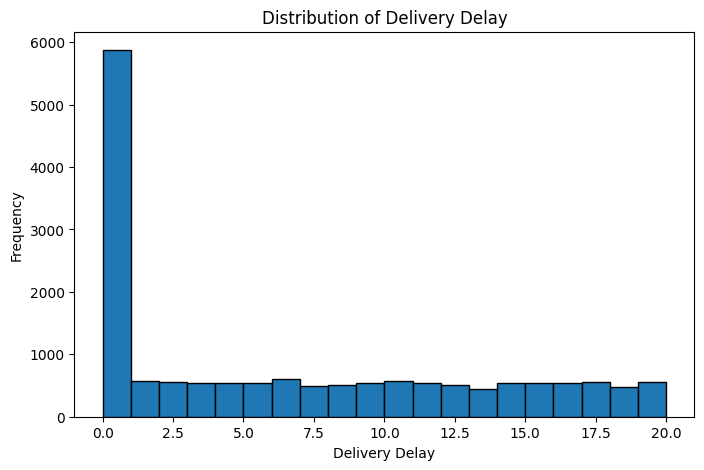

In [83]:
plt.figure(figsize=(8, 5))
plt.hist(df['delivery_delay'], bins=20, edgecolor='black')

plt.title('Distribution of Delivery Delay')
plt.xlabel('Delivery Delay')
plt.ylabel('Frequency')

plt.show()

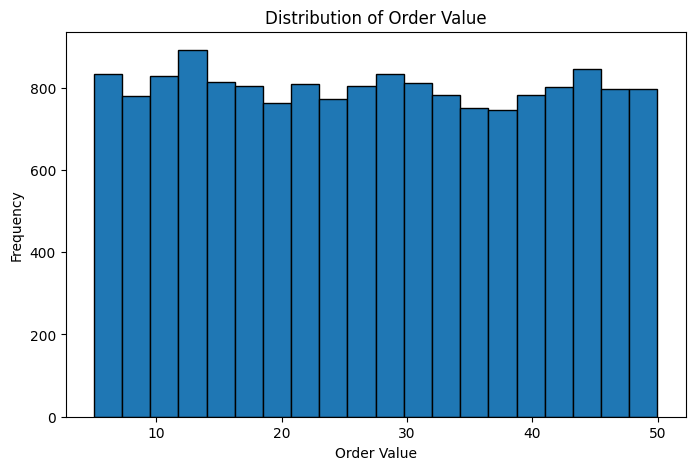

In [84]:
plt.figure(figsize=(8, 5))
plt.hist(df['order_value'], bins=20, edgecolor='black')

plt.title('Distribution of Order Value')
plt.xlabel('Order Value')
plt.ylabel('Frequency')

plt.show()

In [87]:
print(df['delivery_delay'].head(10))
print(df['delivery_delay'].dtype)
print(df['delivery_delay'].isnull().sum())
print(df['delivery_delay'].describe())

0    17.15
1    16.04
2     9.09
3     0.00
4    12.20
5     0.00
6     0.35
7     0.00
8    15.55
9     9.38
Name: delivery_delay, dtype: float64
float64
1
count    16037.000000
mean         6.625569
std          6.660187
min          0.000000
25%          0.000000
50%          4.900000
75%         12.340000
max         20.000000
Name: delivery_delay, dtype: float64


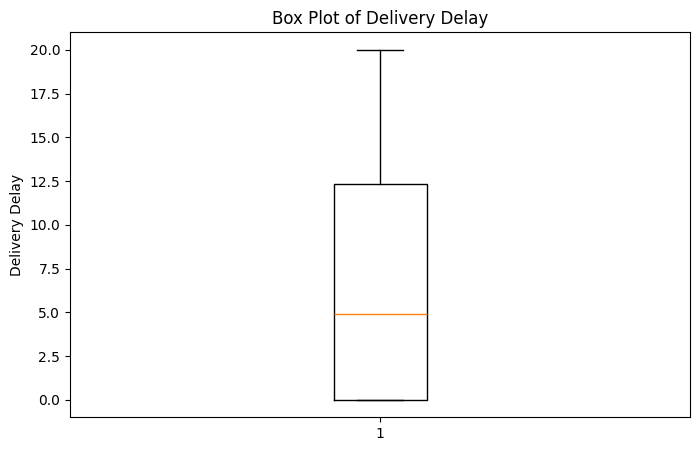

In [88]:
plt.figure(figsize=(8, 5))

plt.boxplot(df['delivery_delay'].dropna())

plt.title('Box Plot of Delivery Delay')
plt.ylabel('Delivery Delay')

plt.show()

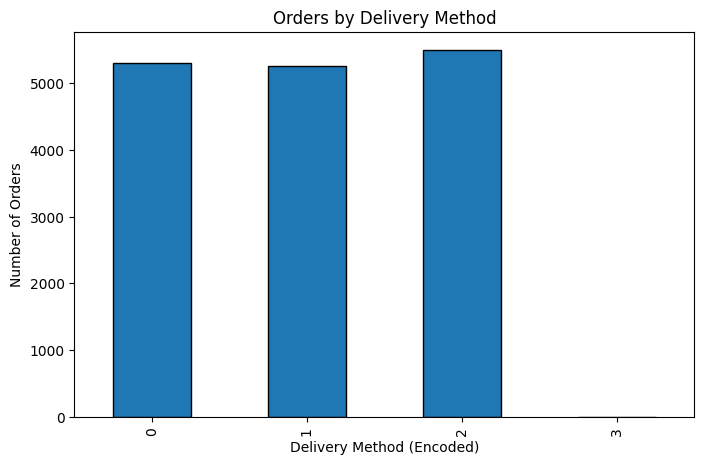

In [89]:
plt.figure(figsize=(8, 5))

df['delivery_method'].value_counts().sort_index().plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Orders by Delivery Method')
plt.xlabel('Delivery Method (Encoded)')
plt.ylabel('Number of Orders')

plt.show()

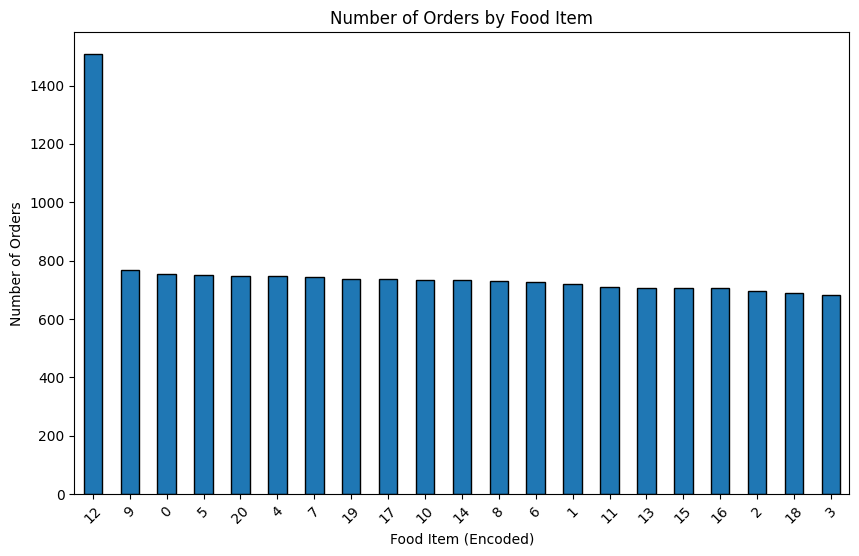

In [90]:
plt.figure(figsize=(10, 6))

df['food_item'].value_counts().sort_values(ascending=False).plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Number of Orders by Food Item')
plt.xlabel('Food Item (Encoded)')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)

plt.show()

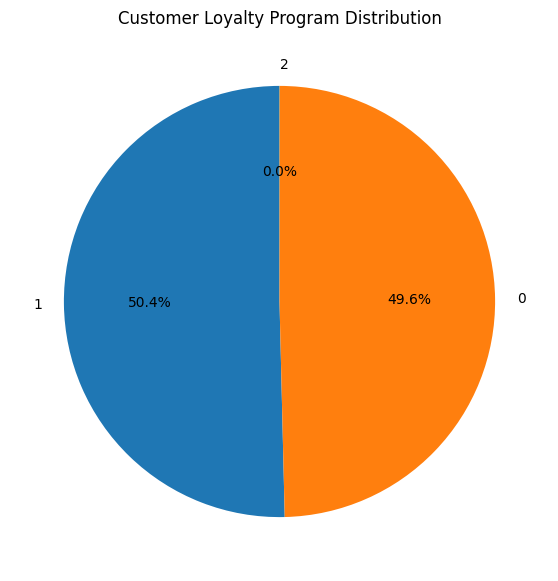

In [91]:
plt.figure(figsize=(7, 7))

df['loyalty_program'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Loyalty Program Distribution')
plt.ylabel('')

plt.show()

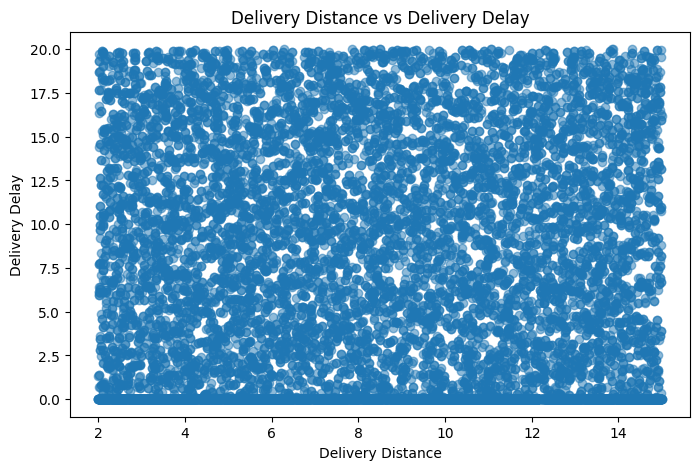

In [92]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['delivery_distance'],
    df['delivery_delay'],
    alpha=0.5
)

plt.title('Delivery Distance vs Delivery Delay')
plt.xlabel('Delivery Distance')
plt.ylabel('Delivery Delay')

plt.show()

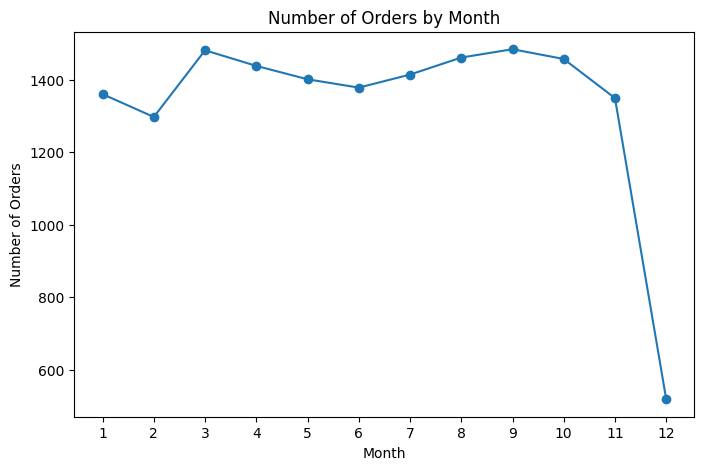

In [93]:
monthly_orders = df['order_month'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.plot(
    monthly_orders.index,
    monthly_orders.values,
    marker='o'
)

plt.title('Number of Orders by Month')
plt.xlabel('Month')
plt.ylabel('Number of Orders')

plt.xticks(range(1, 13))

plt.show()

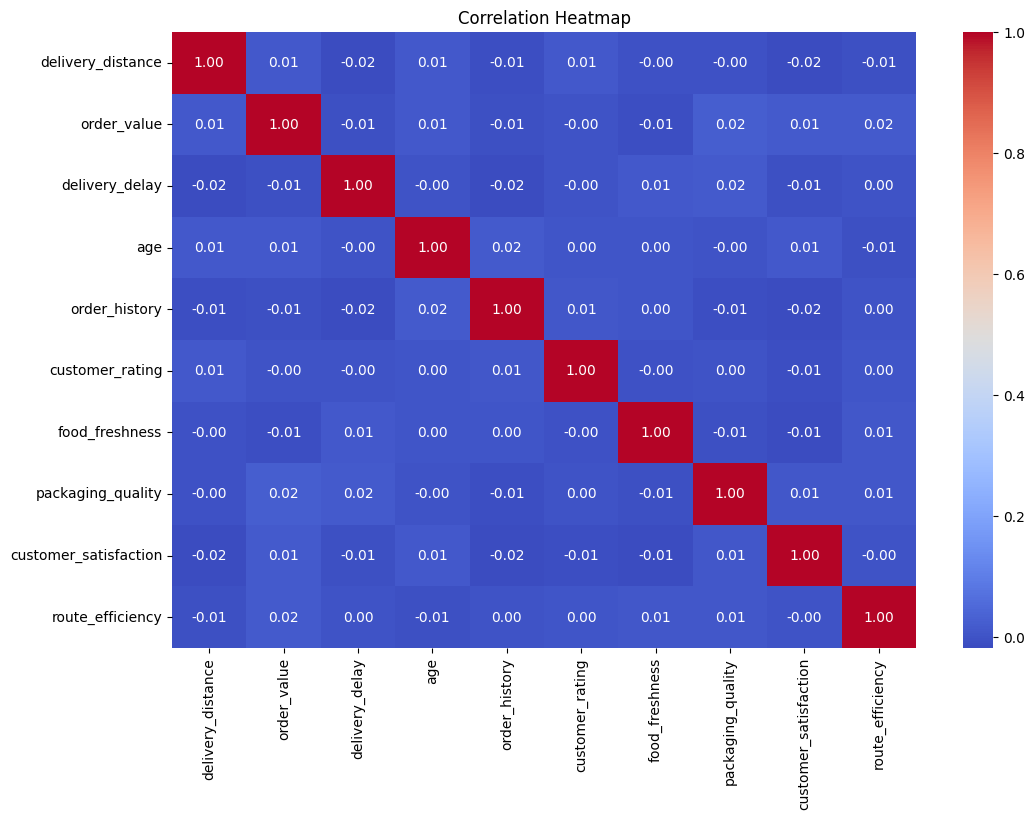

In [94]:
plt.figure(figsize=(12, 8))

correlation = df[numeric_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

Practical - 3

In [95]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform

In [96]:
a = df['delivery_distance'].min()
b = df['delivery_distance'].max()

np.random.seed(42)

random_data = np.random.uniform(a, b, 10000)

print("Minimum:", a)
print("Maximum:", b)

print("Random Mean:", random_data.mean())
print("Random Variance:", random_data.var())

Minimum: 2.0
Maximum: 15.0
Random Mean: 8.424074249895895
Random Variance: 13.980156001507137


In [97]:
dist = uniform(loc=a, scale=b-a)

print("SciPy Mean:", dist.mean())
print("SciPy Variance:", dist.var())

SciPy Mean: 8.5
SciPy Variance: 14.083333333333332


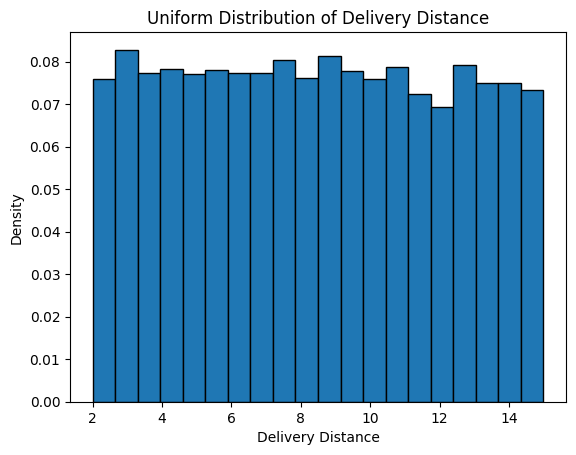

In [98]:
plt.hist(random_data, bins=20, density=True, edgecolor='black')

plt.title('Uniform Distribution of Delivery Distance')
plt.xlabel('Delivery Distance')
plt.ylabel('Density')

plt.show()

In [99]:
print("----- Comparison -----")

print("Random Mean:", random_data.mean())
print("SciPy Mean:", dist.mean())

print("Random Variance:", random_data.var())
print("SciPy Variance:", dist.var())

----- Comparison -----
Random Mean: 8.424074249895895
SciPy Mean: 8.5
Random Variance: 13.980156001507137
SciPy Variance: 14.083333333333332


Normal Distribution

In [100]:
mean = df['order_value'].mean()
std = df['order_value'].std()

np.random.seed(42)

random_data = np.random.normal(mean, std, 10000)

print("Mean:", random_data.mean())
print("Standard Deviation:", random_data.std())

Mean: 27.310070110692653
Standard Deviation: 13.104809478136936


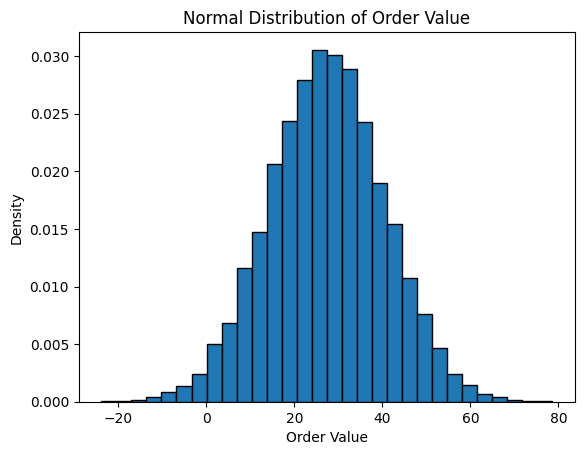

In [101]:
plt.hist(random_data, bins=30, density=True, edgecolor='black')

plt.title('Normal Distribution of Order Value')
plt.xlabel('Order Value')
plt.ylabel('Density')

plt.show()

In [102]:
from scipy.stats import norm

dist = norm(loc=mean, scale=std)

print("SciPy Mean:", dist.mean())
print("SciPy Standard Deviation:", dist.std())

SciPy Mean: 27.337966577290018
SciPy Standard Deviation: 13.060245229306355


Poisson Distribution

In [103]:
lam = df['order_history'].mean()

np.random.seed(42)

random_data = np.random.poisson(lam, 10000)

print("Lambda:", lam)
print("Random Mean:", random_data.mean())
print("Random Variance:", random_data.var())

Lambda: 25.808505331421088
Random Mean: 25.8659
Random Variance: 25.880717190000002


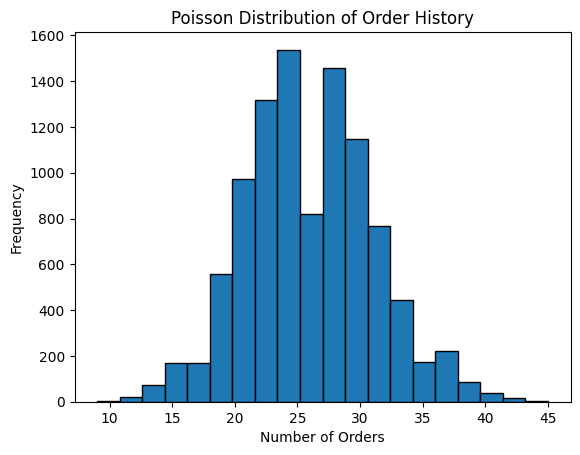

In [104]:
plt.hist(random_data, bins=20, edgecolor='black')

plt.title('Poisson Distribution of Order History')
plt.xlabel('Number of Orders')
plt.ylabel('Frequency')

plt.show()

In [105]:
from scipy.stats import poisson

dist = poisson(mu=lam)

print("SciPy Mean:", dist.mean())
print("SciPy Variance:", dist.var())

SciPy Mean: 25.808505331421088
SciPy Variance: 25.808505331421088


Binomial Distribution

In [128]:
import numpy as np

n_small = 10

# Define probability of success p (e.g., proportion of high satisfaction ratings >= 4)
p = (df['customer_satisfaction'] >= 4).mean()

random_small = np.random.binomial(n_small, p, 10000)

print("Random Mean:", random_small.mean())
print("Random Variance:", random_small.var())

Random Mean: 3.9278
Random Variance: 2.36918716


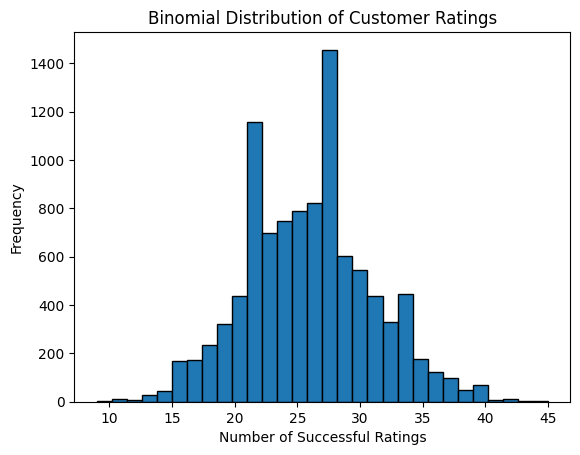

In [107]:
plt.hist(random_data, bins=30, edgecolor='black')

plt.title('Binomial Distribution of Customer Ratings')
plt.xlabel('Number of Successful Ratings')
plt.ylabel('Frequency')

plt.show()

In [127]:
from scipy.stats import binom

# Define probability of success p (e.g., proportion of high satisfaction ratings >= 4)
p = (df['customer_satisfaction'] >= 4).mean()

dist_small = binom(n_small, p)

print("Probability of success p:", p)
print("SciPy Mean:", dist_small.mean())
print("SciPy Variance:", dist_small.var())

prob = dist_small.pmf(5)
print("P(X = 5):", prob)

Probability of success p: 0.3937523381967826
SciPy Mean: 3.9375233819678264
SciPy Variance: 2.387114343613492
P(X = 5): 0.19532896668323863


Practical -4
Simple Random Sampling

In [109]:
import numpy as np
import pandas as pd

np.random.seed(42)

sample = df['order_value'].sample(n=100, random_state=42)

print("Random Sample:")
print(sample.head(10))

print("\nSample Size:", len(sample))

Random Sample:
13094    12.19
4045      5.83
4147     28.18
9367     33.04
13203    42.89
5838      9.19
6805     22.53
13665    48.96
6535     39.58
4740     11.38
Name: order_value, dtype: float64

Sample Size: 100


In [110]:
sample_mean = sample.mean()

print("Sample Mean:", sample_mean)

Sample Mean: 25.091000000000005


In [111]:
population_mean = df['order_value'].mean()

print("Population Mean:", population_mean)

Population Mean: 27.337966577290018


In [112]:
print("Population Mean:", population_mean)
print("Sample Mean:", sample_mean)
print("Difference:", abs(population_mean - sample_mean))

Population Mean: 27.337966577290018
Sample Mean: 25.091000000000005
Difference: 2.2469665772900136


Random Sampling Using NumPy

In [113]:
np.random.seed(42)

random_sample = np.random.choice(
    df['order_value'],
    size=100,
    replace=False
)

print("Random Sample using NumPy:")
print(random_sample[:10])

print("\nSample Mean:", random_sample.mean())

Random Sample using NumPy:
[12.19  5.83 28.18 33.04 42.89  9.19 22.53 48.96 39.58 11.38]

Sample Mean: 25.091000000000005


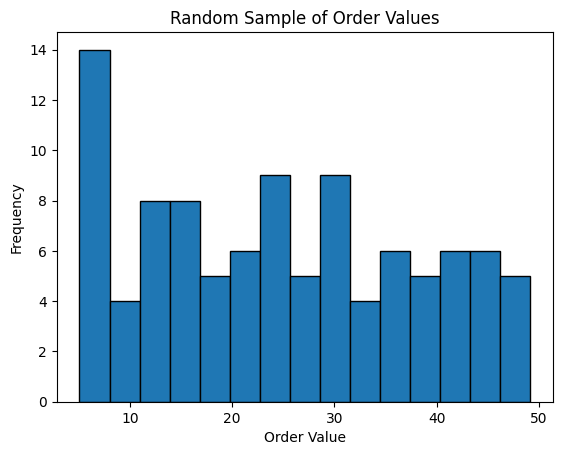

In [114]:
import matplotlib.pyplot as plt

plt.hist(random_sample, bins=15, edgecolor='black')

plt.title('Random Sample of Order Values')
plt.xlabel('Order Value')
plt.ylabel('Frequency')

plt.show()

In [115]:
population_mean = df['order_value'].mean()

print("Population Mean:", population_mean)

Population Mean: 27.337966577290018


In [116]:
sample_means = []

for i in range(10):
    sample = df['order_value'].sample(n=100, random_state=i)
    sample_means.append(sample.mean())

print("Sample Means:")
print(sample_means)

Sample Means:
[np.float64(25.603499999999993), np.float64(24.929699999999993), np.float64(28.869099999999992), np.float64(27.496800000000004), np.float64(27.7364), np.float64(28.754499999999997), np.float64(27.4568), np.float64(25.3053), np.float64(29.085499999999993), np.float64(29.7575)]


In [117]:
average_sample_mean = np.mean(sample_means)

print("Population Mean:", population_mean)
print("Average of Sample Means:", average_sample_mean)

Population Mean: 27.337966577290018
Average of Sample Means: 27.499509999999997


Population Mean vs Sample Mean


Sampling Distribution of Sample Mean

In [118]:
sample_means = []

for i in range(100):
    sample = df['order_value'].sample(n=30, random_state=i)
    sample_means.append(sample.mean())

print("Number of Sample Means:", len(sample_means))
print("First 10 Sample Means:")
print(sample_means[:10])

Number of Sample Means: 100
First 10 Sample Means:
[np.float64(26.38133333333333), np.float64(26.10533333333333), np.float64(25.190666666666665), np.float64(27.90966666666667), np.float64(27.000666666666667), np.float64(32.162333333333336), np.float64(26.665333333333326), np.float64(26.735333333333337), np.float64(28.77733333333333), np.float64(29.60766666666667)]


In [119]:
sampling_mean = np.mean(sample_means)

print("Mean of Sampling Distribution:", sampling_mean)

Mean of Sampling Distribution: 27.52508689655172


In [120]:
sampling_std = np.std(sample_means)

print("Standard Deviation of Sampling Distribution:", sampling_std)

Standard Deviation of Sampling Distribution: 2.6353659982030826


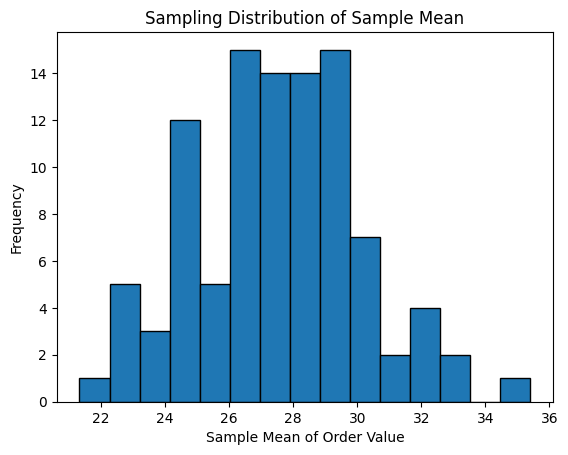

In [121]:
plt.hist(sample_means, bins=15, edgecolor='black')

plt.title('Sampling Distribution of Sample Mean')
plt.xlabel('Sample Mean of Order Value')
plt.ylabel('Frequency')

plt.show()

Central Limit Theorem (CLT)

In [122]:
sample_means = []

for i in range(1000):
    sample = df['order_value'].sample(n=30, random_state=i)
    sample_means.append(sample.mean())

print("Number of Sample Means:", len(sample_means))

Number of Sample Means: 1000


In [123]:
print("Population Mean:", df['order_value'].mean())
print("Mean of Sample Means:", np.mean(sample_means))

Population Mean: 27.337966577290018
Mean of Sample Means: 27.350315689655172


In [124]:
population_std = df['order_value'].std()
sample_size = 30

standard_error = population_std / np.sqrt(sample_size)

print("Standard Error:", standard_error)

Standard Error: 2.384463639546774


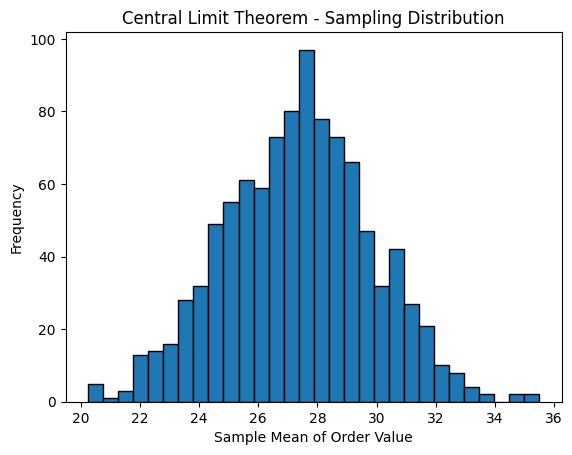

In [125]:
plt.hist(sample_means, bins=30, edgecolor='black')

plt.title('Central Limit Theorem - Sampling Distribution')
plt.xlabel('Sample Mean of Order Value')
plt.ylabel('Frequency')

plt.show()

Original Sample Mean: 6.625568996695143
Bootstrap Mean: 6.6246023670262515
Bootstrap Standard Error: 0.05070793512422659


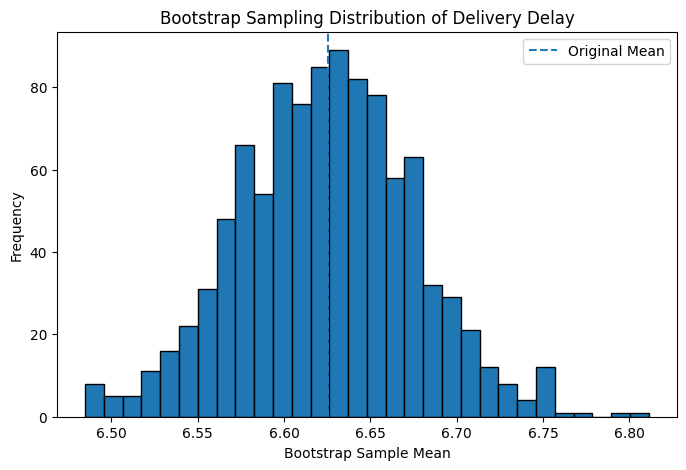

In [154]:
import numpy as np
import matplotlib.pyplot as plt

# Select delivery delay values
data = df['delivery_delay'].dropna().values

# Original sample mean
original_mean = np.mean(data)
print("Original Sample Mean:", original_mean)

# Perform bootstrap sampling
bootstrap_means = []

for i in range(1000):
    sample = np.random.choice(data, size=len(data), replace=True)
    bootstrap_means.append(np.mean(sample))

# Calculate bootstrap mean
bootstrap_mean = np.mean(bootstrap_means)

print("Bootstrap Mean:", bootstrap_mean)
print("Bootstrap Standard Error:", np.std(bootstrap_means))

# Plot bootstrap distribution
plt.figure(figsize=(8, 5))
plt.hist(bootstrap_means, bins=30, edgecolor='black')
plt.axvline(original_mean, linestyle='--', label='Original Mean')
plt.xlabel("Bootstrap Sample Mean")
plt.ylabel("Frequency")
plt.title("Bootstrap Sampling Distribution of Delivery Delay")
plt.legend()
plt.show()

Population Mean: 6.625568996695143
Population Median: 4.9
Population Standard Deviation: 6.660187007780255
Population Size: 16037


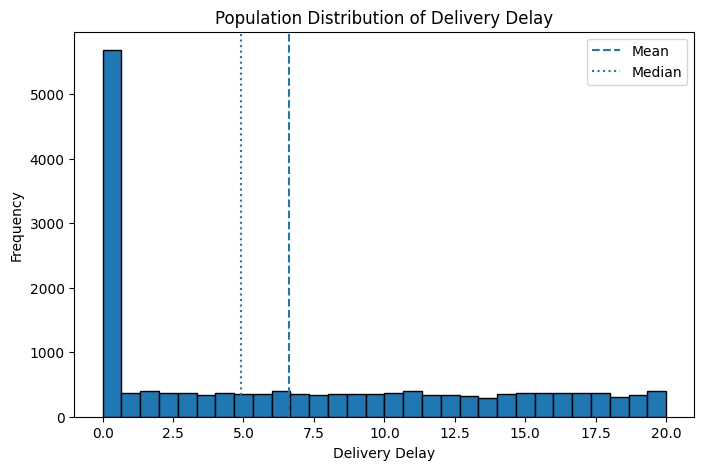

In [155]:
import matplotlib.pyplot as plt

# Select population data
population = df['delivery_delay'].dropna()

# Calculate population statistics
print("Population Mean:", population.mean())
print("Population Median:", population.median())
print("Population Standard Deviation:", population.std())
print("Population Size:", len(population))

# Plot population distribution
plt.figure(figsize=(8, 5))
plt.hist(population, bins=30, edgecolor='black')
plt.axvline(population.mean(), linestyle='--', label='Mean')
plt.axvline(population.median(), linestyle=':', label='Median')

plt.xlabel("Delivery Delay")
plt.ylabel("Frequency")
plt.title("Population Distribution of Delivery Delay")
plt.legend()
plt.show()

Mean: 6.625568996695143
Median: 4.9
Skewness: 0.5175525032882538
The distribution is positively skewed.


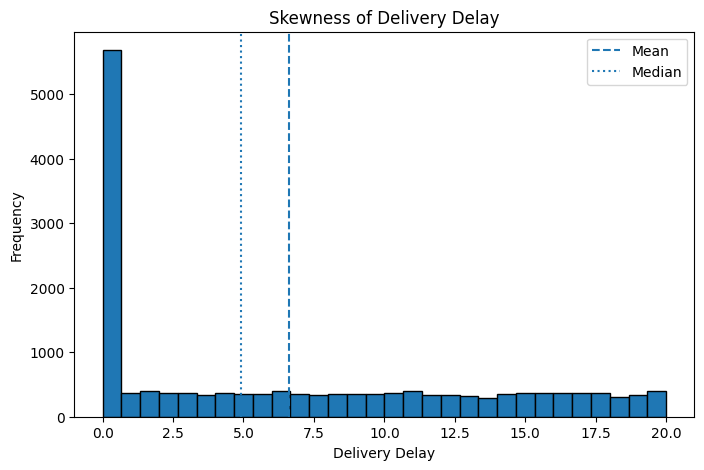

In [156]:
import matplotlib.pyplot as plt

# Select delivery delay data
data = df['delivery_delay'].dropna()

# Calculate skewness
skewness = data.skew()

print("Mean:", data.mean())
print("Median:", data.median())
print("Skewness:", skewness)

if skewness > 0:
    print("The distribution is positively skewed.")
elif skewness < 0:
    print("The distribution is negatively skewed.")
else:
    print("The distribution is symmetric.")

# Plot the distribution
plt.figure(figsize=(8, 5))
plt.hist(data, bins=30, edgecolor='black')
plt.axvline(data.mean(), linestyle='--', label='Mean')
plt.axvline(data.median(), linestyle=':', label='Median')

plt.xlabel("Delivery Delay")
plt.ylabel("Frequency")
plt.title("Skewness of Delivery Delay")
plt.legend()
plt.show()

Practical - 5

Covariance, Pearson and Spearman Correlation

Aim: To study the relationship between delivery distance and delivery delay using covariance, Pearson correlation and Spearman correlation.

In [129]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr

print(df.shape)
print(df.columns)

(16038, 35)
Index(['order_id', 'restaurant_id', 'food_item', 'order_time', 'delivery_time',
       'delivery_distance', 'order_value', 'delivery_method',
       'traffic_condition', 'weather_condition', 'delivery_delay',
       'route_taken', 'customer_id', 'age', 'gender', 'location',
       'order_history', 'customer_rating', 'preferred_cuisine',
       'order_frequency', 'loyalty_program', 'food_temperature',
       'food_freshness', 'packaging_quality', 'food_condition',
       'customer_satisfaction', 'small_route', 'bike_friendly_route',
       'route_type', 'route_efficiency', 'traffic_avoidance', 'order_hour',
       'order_day', 'order_month', 'delivery_hour'],
      dtype='object')


In [130]:
data = df[['delivery_distance', 'delivery_delay']].dropna()

x = data['delivery_distance']
y = data['delivery_delay']

print(data.head())

   delivery_distance  delivery_delay
0               2.17           17.15
1              13.40           16.04
2              10.74            9.09
3               6.29            0.00
4               2.94           12.20


In [132]:
covariance = x.cov(y)

print("Covariance:", covariance)

Covariance: -0.45863176139330664


In [133]:
pearson_corr, pearson_p = pearsonr(x, y)

print("Pearson Correlation:", pearson_corr)
print("P-value:", pearson_p)

Pearson Correlation: -0.018251280808434835
P-value: 0.02081602243051928


In [134]:
spearman_corr, spearman_p = spearmanr(x, y)

print("Spearman Correlation:", spearman_corr)
print("P-value:", spearman_p)

Spearman Correlation: -0.02230898723615393
P-value: 0.004723920178348163


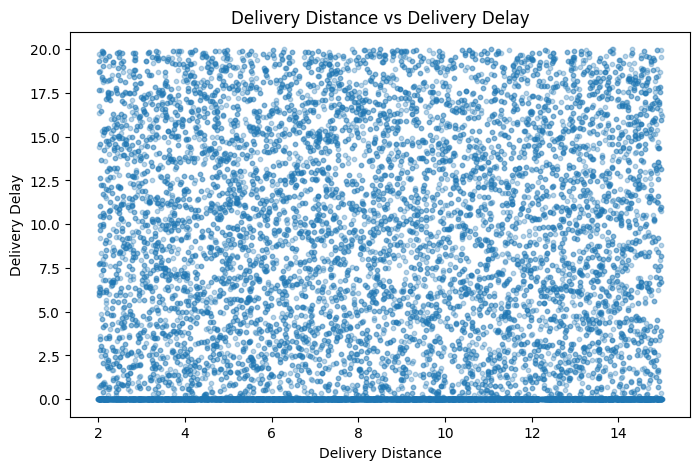

In [136]:
plt.figure(figsize=(8, 5))

plt.scatter(x, y, alpha=0.3, s=10)

plt.xlabel("Delivery Distance")
plt.ylabel("Delivery Delay")
plt.title("Delivery Distance vs Delivery Delay")

plt.show()

In [137]:
print("Covariance:", x.cov(y))

pearson_corr, pearson_p = pearsonr(x, y)
print("Pearson Correlation:", pearson_corr)
print("Pearson P-value:", pearson_p)

spearman_corr, spearman_p = spearmanr(x, y)
print("Spearman Correlation:", spearman_corr)
print("Spearman P-value:", spearman_p)

Covariance: -0.45863176139330664
Pearson Correlation: -0.018251280808434835
Pearson P-value: 0.02081602243051928
Spearman Correlation: -0.02230898723615393
Spearman P-value: 0.004723920178348163


Correlation Hypothesis Testing

Aim: To test whether there is a statistically significant correlation between delivery distance and delivery delay.

In [138]:
alpha = 0.05

print("Pearson Correlation:", pearson_corr)
print("P-value:", pearson_p)

if pearson_p < alpha:
    print("Reject the Null Hypothesis")
    print("There is a significant correlation.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("There is no significant correlation.")

Pearson Correlation: -0.018251280808434835
P-value: 0.02081602243051928
Reject the Null Hypothesis
There is a significant correlation.


In [139]:
print("Spearman Correlation:", spearman_corr)
print("P-value:", spearman_p)

if spearman_p < alpha:
    print("Reject the Null Hypothesis")
    print("There is a significant monotonic relationship.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("There is no statistically significant monotonic relationship.")

Spearman Correlation: -0.02230898723615393
P-value: 0.004723920178348163
Reject the Null Hypothesis
There is a significant monotonic relationship.


The correlation hypothesis tests were performed between delivery distance and delivery delay using Pearson and Spearman correlation methods. Both p-values were less than 0.05; therefore, the null hypothesis was rejected for both tests. However, the correlation coefficients were close to zero, indicating a very weak negative relationship between the variables.

Comparison of Hypothesized Mean and Sample Mean.

Sample Mean: 6.625568996695143
Hypothesized Mean: 10


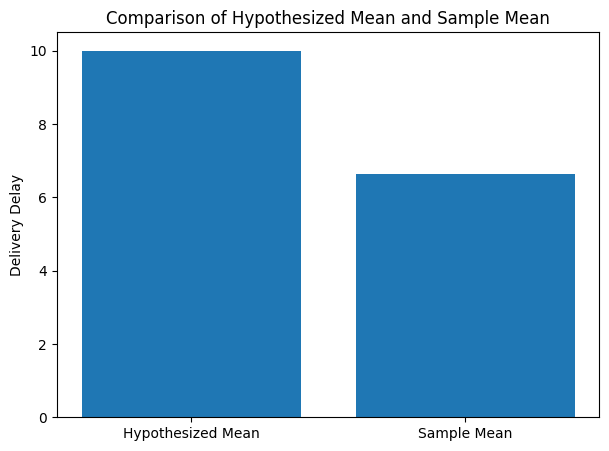

In [159]:
import matplotlib.pyplot as plt

data = df['delivery_delay'].dropna()

sample_mean = data.mean()
hypothesized_mean = 10

print("Sample Mean:", sample_mean)
print("Hypothesized Mean:", hypothesized_mean)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Hypothesized Mean", "Sample Mean"],
    [hypothesized_mean, sample_mean]
)

plt.ylabel("Delivery Delay")
plt.title("Comparison of Hypothesized Mean and Sample Mean")
plt.show()

One-Sample Z-Test(Two-Tailed)

In [157]:
import numpy as np
from scipy.stats import norm

data = df['delivery_delay'].dropna()

# Hypothesized population mean
mu = 10

# Sample statistics
sample_mean = data.mean()
sample_std = data.std()
n = len(data)

# Z-test calculation
z_score = (sample_mean - mu) / (sample_std / np.sqrt(n))

# Two-tailed p-value
p_value = 2 * (1 - norm.cdf(abs(z_score)))

print("Sample Mean:", sample_mean)
print("Hypothesized Mean:", mu)
print("Z-Score:", z_score)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis (H0)")
    print("The sample mean is significantly different from 10.")
else:
    print("Fail to Reject the Null Hypothesis (H0)")
    print("There is no significant difference from 10.")

Sample Mean: 6.625568996695143
Hypothesized Mean: 10
Z-Score: -64.1616750655748
P-Value: 0.0
Reject the Null Hypothesis (H0)
The sample mean is significantly different from 10.


One-Sample Z-Test

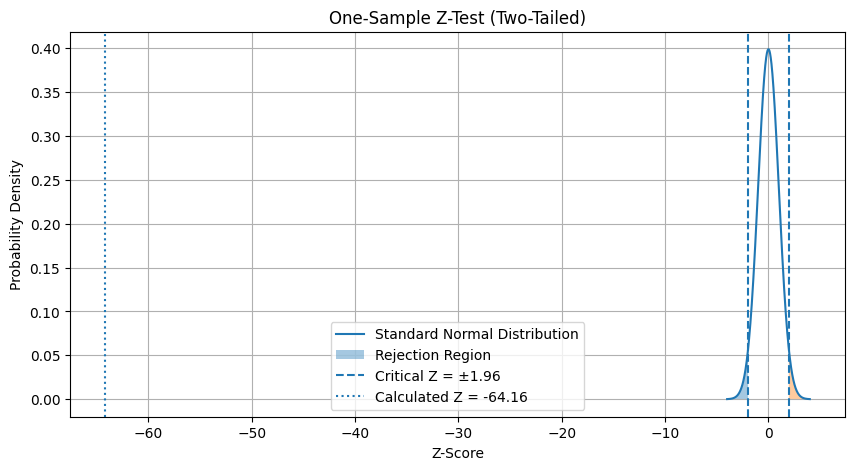

Calculated Z-Score: -64.1616750655748
Critical Z-Values: -1.96 and +1.96


In [158]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu = 10
sample_mean = df['delivery_delay'].dropna().mean()
data = df['delivery_delay'].dropna()
n = len(data)
sample_std = data.std()

z_score = (sample_mean - mu) / (sample_std / np.sqrt(n))
critical_z = 1.96

x = np.linspace(-4, 4, 1000)
y = norm.pdf(x)

plt.figure(figsize=(10, 5))
plt.plot(x, y, label='Standard Normal Distribution')

plt.fill_between(x, y, where=(x <= -critical_z),
                 alpha=0.4, label='Rejection Region')
plt.fill_between(x, y, where=(x >= critical_z), alpha=0.4)

plt.axvline(-critical_z, linestyle='--', label='Critical Z = ±1.96')
plt.axvline(critical_z, linestyle='--')
plt.axvline(z_score, linestyle=':', label=f'Calculated Z = {z_score:.2f}')

plt.xlabel('Z-Score')
plt.ylabel('Probability Density')
plt.title('One-Sample Z-Test (Two-Tailed)')
plt.legend()
plt.grid(True)
plt.show()

print("Calculated Z-Score:", z_score)
print("Critical Z-Values: -1.96 and +1.96")

One-Sample t-Test

Aim: To determine whether the mean delivery delay is significantly different from a hypothesized value.

In [140]:
from scipy.stats import ttest_1samp

In [141]:
delivery_delay = df['delivery_delay'].dropna()

t_stat, p_value = ttest_1samp(delivery_delay, 10)

print("Sample Mean:", delivery_delay.mean())
print("Hypothesized Mean: 10")
print("T-statistic:", t_stat)
print("P-value:", p_value)

Sample Mean: 6.625568996695143
Hypothesized Mean: 10
T-statistic: -64.16167506557494
P-value: 0.0


In [142]:
alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis")
    print("Mean delivery delay is significantly different from 10 minutes.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("Mean delivery delay is not significantly different from 10 minutes.")

Reject the Null Hypothesis
Mean delivery delay is significantly different from 10 minutes.


The One-Sample t-Test was performed to compare the mean delivery delay with the hypothesized mean of 10 minutes. Since the p-value was less than the significance level of 0.05, the null hypothesis was rejected. Therefore, the mean delivery delay is statistically significantly different from 10 minutes.

Independent Two-Sample t-Test

Aim: To compare the mean delivery delay between two independent traffic-condition groups.

In [143]:
from scipy.stats import ttest_ind

In [144]:
print(df['traffic_condition'].value_counts())

traffic_condition
1    5439
2    5367
0    5231
3       1
Name: count, dtype: int64


In [145]:
from scipy.stats import ttest_ind

group1 = df[df['traffic_condition'] == 0]['delivery_delay'].dropna()
group2 = df[df['traffic_condition'] == 1]['delivery_delay'].dropna()

print("Group 1 Mean:", group1.mean())
print("Group 2 Mean:", group2.mean())
print("Group 1 Size:", len(group1))
print("Group 2 Size:", len(group2))

Group 1 Mean: 6.655180653794686
Group 2 Mean: 6.748736900165472
Group 1 Size: 5231
Group 2 Size: 5439


In [146]:
t_stat, p_value = ttest_ind(group1, group2, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -0.7241305941254356
P-value: 0.46900146269270726


In [147]:
alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis")
    print("The mean delivery delays are significantly different.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("There is no significant difference in mean delivery delays.")

Fail to Reject the Null Hypothesis
There is no significant difference in mean delivery delays.


Paired t-Test

Aim: To compare two related sets of measurements using a paired t-test.

In [148]:
import pandas as pd

original_df = pd.read_csv('food_delivery_dataset.csv')
cleaned_df = pd.read_csv('food_delivery_cleaned.csv')

print("Original dataset shape:", original_df.shape)
print("Cleaned dataset shape:", cleaned_df.shape)

print("\nOriginal delivery delays:")
print(original_df['delivery_delay'].describe())

print("\nCleaned delivery delays:")
print(cleaned_df['delivery_delay'].describe())

print("\nNegative delays in original dataset:",
      (original_df['delivery_delay'] < 0).sum())

Original dataset shape: (20000, 31)
Cleaned dataset shape: (16038, 35)

Original delivery delays:
count    20000.000000
mean         4.952421
std          8.624563
min        -10.000000
25%         -2.430000
50%          4.900000
75%         12.320000
max         20.000000
Name: delivery_delay, dtype: float64

Cleaned delivery delays:
count    16037.000000
mean         6.625569
std          6.660187
min          0.000000
25%          0.000000
50%          4.900000
75%         12.340000
max         20.000000
Name: delivery_delay, dtype: float64

Negative delays in original dataset: 6672


In [149]:
print("Common columns:")
print(set(original_df.columns) & set(cleaned_df.columns))

print("\nPossible ID columns:")
print([
    col for col in original_df.columns
    if 'id' in col.lower()
])

Common columns:
{'delivery_time', 'delivery_method', 'preferred_cuisine', 'small_route', 'order_value', 'order_frequency', 'bike_friendly_route', 'food_freshness', 'loyalty_program', 'gender', 'route_type', 'food_temperature', 'order_time', 'delivery_delay', 'route_efficiency', 'route_taken', 'food_condition', 'packaging_quality', 'food_item', 'location', 'customer_rating', 'traffic_condition', 'customer_satisfaction', 'customer_id', 'age', 'order_history', 'restaurant_id', 'order_id', 'traffic_avoidance', 'delivery_distance', 'weather_condition'}

Possible ID columns:
['order_id', 'restaurant_id', 'customer_id', 'traffic_avoidance']


In [150]:
import pandas as pd
from scipy.stats import ttest_rel

# Select the required columns
original = original_df[['order_id', 'delivery_delay']].copy()
cleaned = cleaned_df[['order_id', 'delivery_delay']].copy()

# Rename columns
original = original.rename(
    columns={'delivery_delay': 'original_delay'}
)
cleaned = cleaned.rename(
    columns={'delivery_delay': 'cleaned_delay'}
)

# Match the same orders
paired_data = pd.merge(
    original,
    cleaned,
    on='order_id',
    how='inner',
    validate='many_to_many'
)

# Remove missing values
paired_data = paired_data.dropna(
    subset=['original_delay', 'cleaned_delay']
)

# Perform paired t-test
t_stat, p_value = ttest_rel(
    paired_data['original_delay'],
    paired_data['cleaned_delay']
)

print("Number of paired records:", len(paired_data))
print("Original Mean Delay:", paired_data['original_delay'].mean())
print("Cleaned Mean Delay:", paired_data['cleaned_delay'].mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis")
    print("The mean delivery delays are significantly different.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("No significant difference in mean delivery delays was detected.")

Number of paired records: 16037
Original Mean Delay: 4.972232337719025
Cleaned Mean Delay: 6.625568996695143
T-statistic: -73.05918237004846
P-value: 0.0
Reject the Null Hypothesis
The mean delivery delays are significantly different.


Conclusion: Since the p-value is less than 0.05, we reject the null hypothesis. There is a statistically significant difference between the original and cleaned delivery delays.



One-Way ANOVA

In [151]:
from scipy.stats import f_oneway

# Create groups for traffic conditions 0, 1, and 2
group0 = df[df['traffic_condition'] == 0]['delivery_delay'].dropna()
group1 = df[df['traffic_condition'] == 1]['delivery_delay'].dropna()
group2 = df[df['traffic_condition'] == 2]['delivery_delay'].dropna()

print("Traffic Condition 0 Mean:", group0.mean())
print("Traffic Condition 1 Mean:", group1.mean())
print("Traffic Condition 2 Mean:", group2.mean())

# Perform One-Way ANOVA
f_stat, p_value = f_oneway(group0, group1, group2)

print("\nF-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis")
    print("Mean delivery delays differ significantly across traffic conditions.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("No significant difference in mean delivery delays was detected.")

Traffic Condition 0 Mean: 6.655180653794686
Traffic Condition 1 Mean: 6.748736900165472
Traffic Condition 2 Mean: 6.471887460406187

F-statistic: 2.4109892387637903
P-value: 0.08975901800481718
Fail to Reject the Null Hypothesis
No significant difference in mean delivery delays was detected.


The p-value (0.08976) is greater than the significance level (0.05). Therefore, we fail to reject the null hypothesis. There is no statistically significant difference in mean delivery delays among the three traffic-condition groups.

Chi-Square Test of Independence

In [153]:
import pandas as pd
from scipy.stats import chi2_contingency

# Keep traffic conditions 0, 1, 2 and delivery methods 0, 1, 2
filtered_df = df[
    (df['traffic_condition'].isin([0, 1, 2])) &
    (df['delivery_method'].isin([0, 1, 2]))
]

table = pd.crosstab(
    filtered_df['traffic_condition'],
    filtered_df['delivery_method']
)

chi2, p_value, dof, expected = chi2_contingency(table)

print(table)
print("\nChi-Square Statistic:", chi2)
print("Degrees of Freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the Null Hypothesis")
    print("Traffic condition and delivery method are significantly associated.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("No significant association was detected.")

delivery_method       0     1     2
traffic_condition                  
0                  1744  1750  1737
1                  1736  1769  1934
2                  1817  1730  1820

Chi-Square Statistic: 9.170803558827346
Degrees of Freedom: 4
P-value: 0.056969148591279065
Fail to Reject the Null Hypothesis
No significant association was detected.


The p-value (0.05697) is greater than the significance level (0.05). Therefore, we fail to reject the null hypothesis. There is insufficient statistical evidence of a significant association between traffic condition and delivery method in the analyzed data.
Hypotheses
- H₀: Traffic condition and delivery method are independent.
- H₁: Traffic condition and delivery method are associated.

Linear Regression

Coefficient: -0.016135000718006387
Intercept: 6.774870428182324
Mean Squared Error: 43.169597627678534
R² Score: 0.0008545924541857319


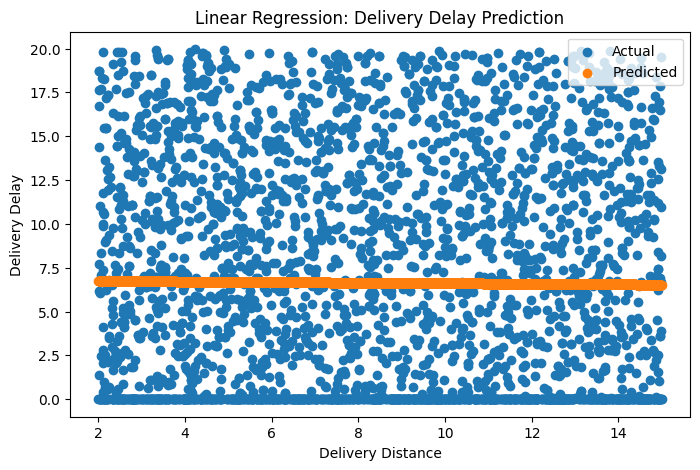

In [160]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

data = df[['delivery_distance', 'delivery_delay']].dropna()

X = data[['delivery_distance']]
y = data['delivery_delay']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

plt.figure(figsize=(8, 5))
plt.scatter(X_test['delivery_distance'], y_test, label='Actual')
plt.scatter(X_test['delivery_distance'], y_pred, label='Predicted')
plt.xlabel("Delivery Distance")
plt.ylabel("Delivery Delay")
plt.title("Linear Regression: Delivery Delay Prediction")
plt.legend()
plt.show()

Ridge Regression

In [161]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

data = df[['delivery_distance', 'delivery_delay']].dropna()

X = data[['delivery_distance']]
y = data['delivery_delay']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

Mean Squared Error: 43.169600504910285
R² Score: 0.0008545258616519114


Decision Tree Regression

Mean Squared Error: 42.99742743680747
R² Score: 0.004839411979462249


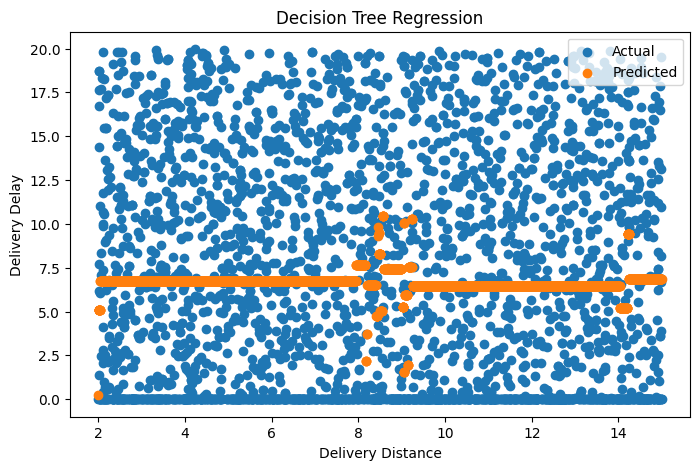

In [162]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

data = df[['delivery_distance', 'delivery_delay']].dropna()

X = data[['delivery_distance']]
y = data['delivery_delay']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

plt.figure(figsize=(8, 5))
plt.scatter(X_test['delivery_distance'], y_test, label='Actual')
plt.scatter(X_test['delivery_distance'], y_pred, label='Predicted')
plt.xlabel("Delivery Distance")
plt.ylabel("Delivery Delay")
plt.title("Decision Tree Regression")
plt.legend()
plt.show()

Random Forest Regression

Mean Squared Error: 42.98588087395452
R² Score: 0.005106653183491128


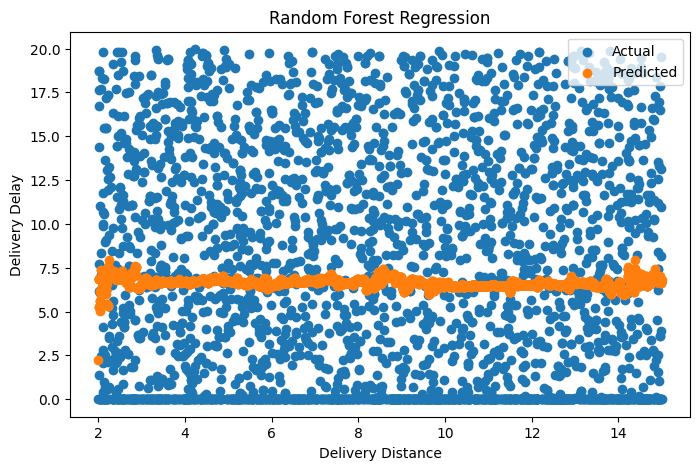

In [163]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

data = df[['delivery_distance', 'delivery_delay']].dropna()

X = data[['delivery_distance']]
y = data['delivery_delay']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

plt.figure(figsize=(8, 5))
plt.scatter(X_test['delivery_distance'], y_test, label='Actual')
plt.scatter(X_test['delivery_distance'], y_pred, label='Predicted')
plt.xlabel("Delivery Distance")
plt.ylabel("Delivery Delay")
plt.title("Random Forest Regression")
plt.legend()
plt.show()

Lasso Regression

Mean Squared Error: 43.210261266395904
R² Score: -8.655340102881048e-05


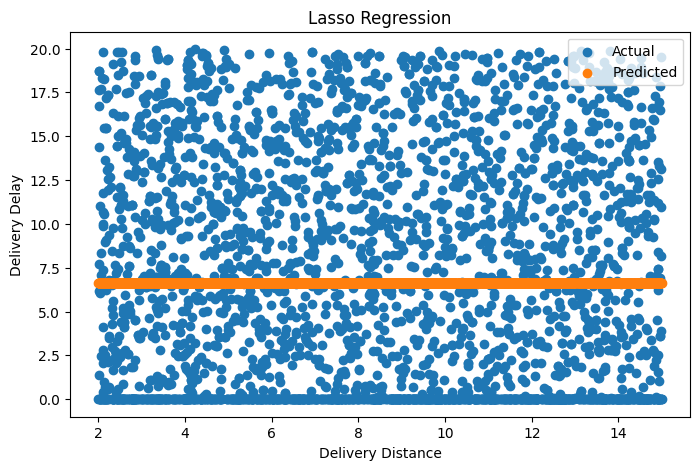

In [164]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

data = df[['delivery_distance', 'delivery_delay']].dropna()

X = data[['delivery_distance']]
y = data['delivery_delay']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=1.0, max_iter=10000)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

plt.figure(figsize=(8, 5))
plt.scatter(X_test['delivery_distance'], y_test, label='Actual')
plt.scatter(X_test['delivery_distance'], y_pred, label='Predicted')
plt.xlabel("Delivery Distance")
plt.ylabel("Delivery Delay")
plt.title("Lasso Regression")
plt.legend()
plt.show()

In [165]:
def predict_delay(distance):
    prediction = model.predict([[distance]])[0]
    return f"Predicted Delivery Delay: {prediction:.2f}"

In [166]:
import gradio as gr

interface = gr.Interface(
    fn=predict_delay,
    inputs=gr.Number(label="Enter Delivery Distance"),
    outputs="text",
    title="Food Delivery Delay Prediction System",
    description="Enter delivery distance to predict delivery delay."
)

interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://000feabd57ffa5d99c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
